# *IPECC* Dataset Presentation

This notebook contains basic information to understand the content of [IPECC](https://demo.data.gouv.fr/datasets/ascad-ipecc-tches-2027) used in the publication [LINK TO PAPER](http://iacr.org).

Due to the depackaging and probe positioning, exact replicability is hard to achieve. However, we expect that interested researchers willing to take their own set of traces will be able to put themselves in very similar conditions based on the provided information.

## Aim of this Dataset

The goal of publishing such dataset is to provide to the community traces corresponding to a state-of-the-art FPGA ECC accelerator so that testing and benchmarking attacks will be easier and fairer.

## Datasets Configurations

We provide 11 datasets, each one containing 900 EM traces of scalar multiplication computed over the elliptic curve FRP256v1. In the table below, we detail the security configurations of the 11 datasets showcasing the different countermeasures enabled for each dataset. Each line of the table corresponds to one of the 11 configurations, thus one of the 11 datasets. 

<!-- 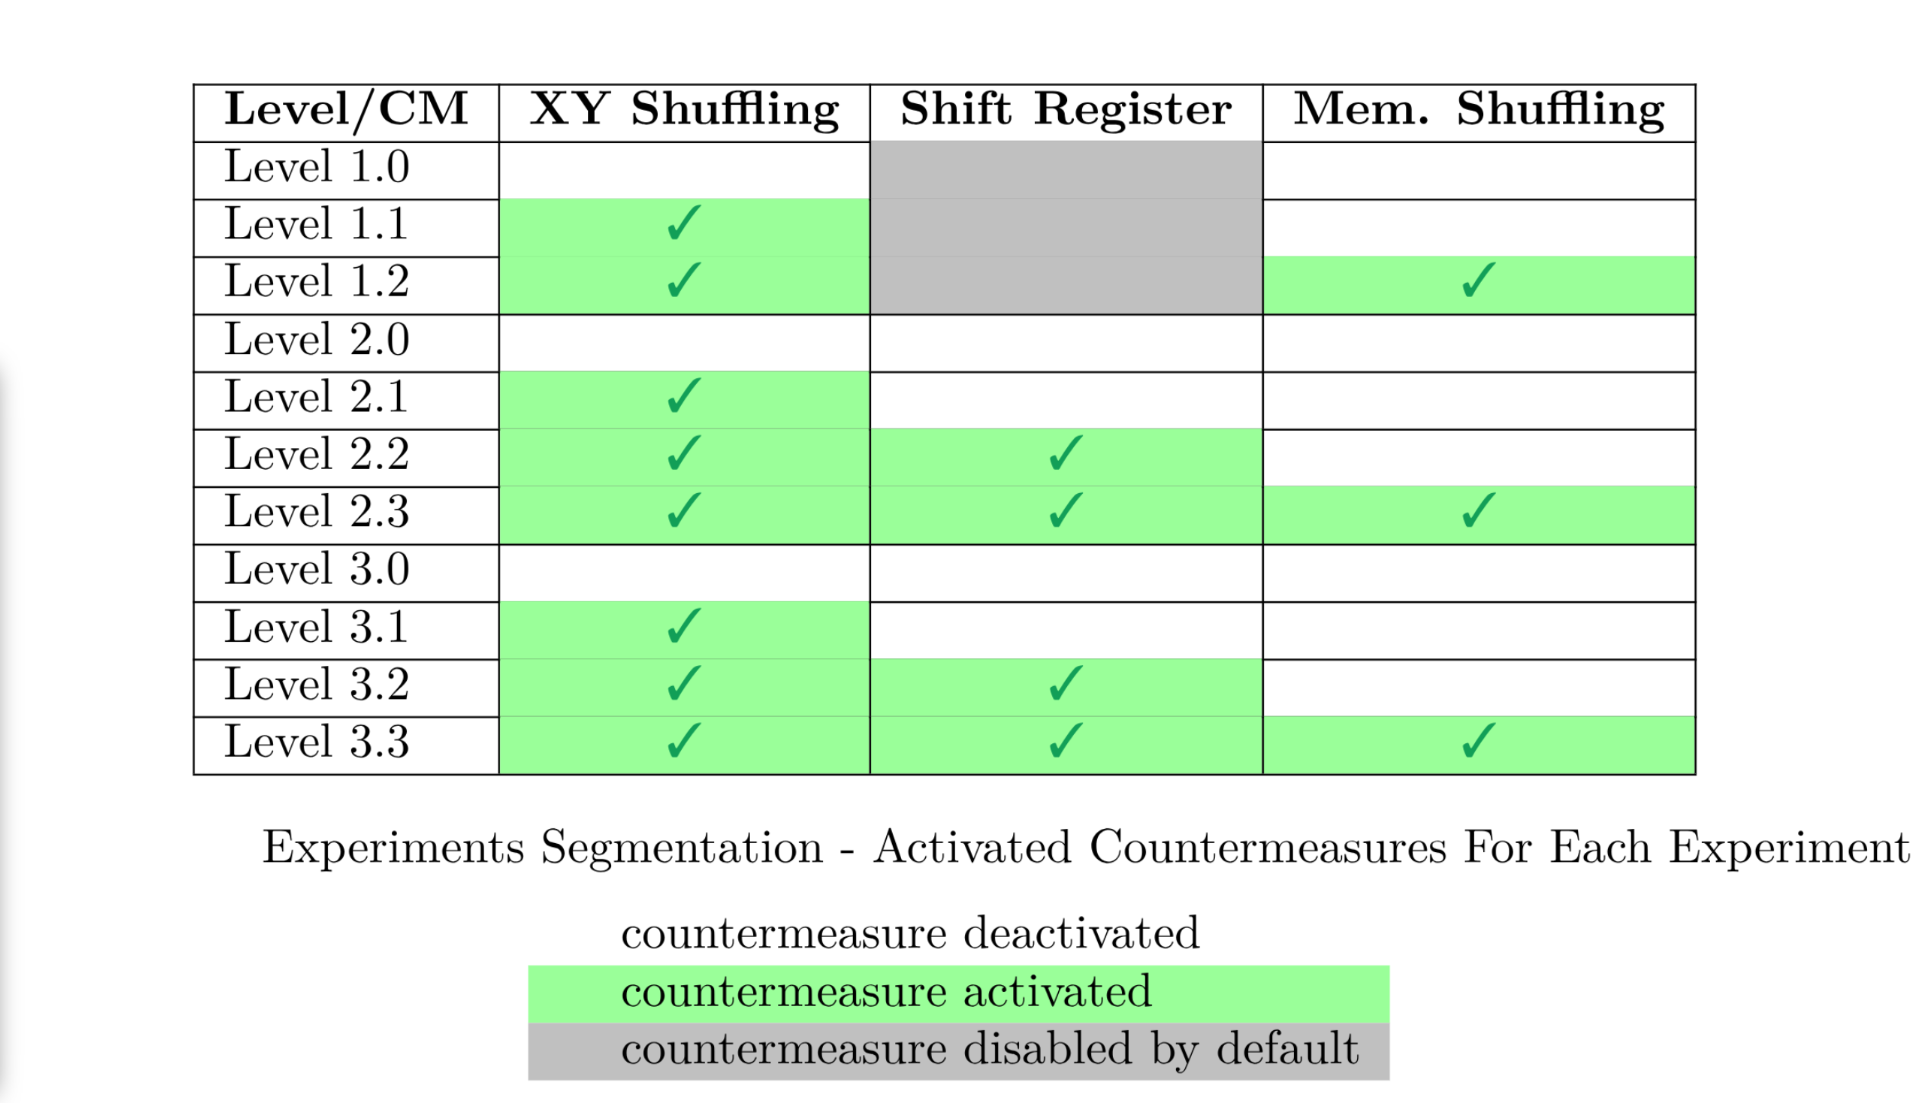 -->

| Level/Countermeasure | XY Shuffling | Shift Register | Memory Shuffling |
|:--------------------:|:------------:|:--------------:|:----------------:|
|       Level 1.0      |              |       ❌       |                  |
|       Level 1.1      |      ✅      |       ❌       |                  |
|       Level 1.3      |      ✅      |       ❌       |        ✅        |
|       Level 2.0      |              |                |                  |
|       Level 2.1      |      ✅      |                |                  |
|       Level 2.2      |      ✅      |       ✅       |                  |
|       Level 2.3      |      ✅      |       ✅       |        ✅        |
|       Level 3.0      |              |                |                  |
|       Level 3.1      |      ✅      |                |                  |
|       Level 3.2      |      ✅      |       ✅       |                  |
|       Level 3.3      |      ✅      |       ✅       |        ✅        |

The accelerator presented in [LINK TO PAPER](http://iacr.org) is of particular interest since it has easily tunable countermeasures. This may ease the analysis of an attack robustness to some protections or the assessment of a countermesure efficiency against some attacks.

## Dataset Content

We thus propose a dataset that is, actually, a set of datasets corresponding to different security levels of the IP (in the sense of the activated countermeasures not the curve size).

## Dataset Format

### Structure

Let us now see how a single file is structured.

A file corresponds to the traces obtained for a given security configuration of the IP and uses the [HDF5](https://www.hdfgroup.org/solutions/hdf5/) file format which is a good solution to handle large data and its associated information.

In [1]:
import h5py
import matplotlib.pyplot as plt
import os
# Please fill the next variable with the path of the downloaded dataset file.
PATH_TO_DATA = "test_level3-1/ipecc_level_3-1_part_0.h5"

if not os.path.exists(PATH_TO_DATA):
    print(f"Warning! File not found, please ensure PATH_TO_DATA has been set to the location of a dataset Hdf5 file.")

Below is the structure of the file. A context manager is used for opening/closing the HDF5 file. The list of the HDF5 datasets (which basically corresponds to a numpy array) is then printed.

In [2]:
with h5py.File(PATH_TO_DATA) as file_handler:
    # the function call the lambda with the name and the reference to each object
    file_handler.visititems(lambda x,y: print(f"{x:17s}{y}"))

em_curves        <HDF5 dataset "em_curves": shape (100, 150000000), type "<i2">
inputs           <HDF5 group "/inputs" (4 members)>
inputs/phi       <HDF5 dataset "phi": shape (100, 48), type "|u1">
inputs/point_x   <HDF5 dataset "point_x": shape (100, 32), type "|u1">
inputs/point_y   <HDF5 dataset "point_y": shape (100, 32), type "|u1">
inputs/scalar    <HDF5 dataset "scalar": shape (100, 32), type "|u1">


### Meta-data
Additional information can be found as group/datasets attributes.

#### 1. Global Experiment Information
Global information about the experiment (that is essentially the target description) can be found as attributes of the file root.

In [3]:
with h5py.File(PATH_TO_DATA) as file_handler:
    for k, v in file_handler.attrs.items():
        print(f"{k:25s}: {v}")

dut.board.model          : Arty Z7-010
dut.board.pn             : 410-346-10
dut.curve.a              : [241 253  23 140  11  58 213 143  16  18 109 232 206  66  67  91  57  97
 173 188 171 200 202 109 232 252 243  83 216 110 156   0]
dut.curve.b              : [238  53  63 202  84  40 169  48  13  74 186 117  74  68 192  15 223 236
  12 154 228 177 161 128  48 117 237 150 123 123 183  63]
dut.curve.bit_size       : 256
dut.curve.generator_x    : [182 179 212 195  86 193  57 235  49  24  61  71  73 212  35 149 140  39
 210 220 175 152 183   1 100 201 122  45 217 143  92 255]
dut.curve.generator_y    : [ 97  66 224 247 200 178   4 145  31 146 113 240 243 236 239 140  39   1
 195   7 232 228 201 225 131  17  90  21  84   6  44 251]
dut.curve.modulo         : [241 253  23 140  11  58 213 143  16  18 109 232 206  66  67  91  57  97
 173 188 171 200 202 109 232 252 243  83 216 110 156   3]
dut.curve.name           : FRP256v1
dut.curve.order          : [241 253  23 140  11  58 213 143  16  1

#### 2. Channel Specific Information
Information specific to a measurement channel (here, EM curves only are available) can be found as attributes of the corresponding dataset.

In [4]:
with h5py.File(PATH_TO_DATA) as file_handler:
    for k, v in file_handler["em_curves"].attrs.items():
        print(f"{k:25s}: {v}")

probe                    : Langer ICR-HH 500-6
scope.adc_precision      : 10
scope.bandwidth          : 500000000.0
scope.coupling           : DC50
scope.duration           : 0.05
scope.model              : Picoscope 6424E
scope.sample_rate        : 5000000000.0
scope.voltage_amplitude  : 0.4


### Inputs
The inputs corresponding to the measurements/curves are stored in a dedicated dataset in the group named `inputs` as previously seen.

Below is an example showing the array corresponding to the scalar used for the first trace acquisition and the corresponding input point where the byte order for reconstructing the big integer is explicited.

In [5]:
with h5py.File(PATH_TO_DATA) as file_handler:
    print(file_handler["inputs/scalar"][0, :])

    point = (
        int.from_bytes(file_handler["inputs/point_x"][0, :], byteorder="big"),
        int.from_bytes(file_handler["inputs/point_y"][0, :], byteorder="big"),
    )

    print(point)
    print(hex(point[0]))

[ 36 181  84  91 211  56 116 151  32 195 125 127  22 179 184 220 126 191
 161 201 227  15  94  25  90 231 222 169 150  82 129 225]
(42613984201041121658572148081120429258067276263745542155204821519303612581308, 10539643973628123262135020271213041199901504001332359121990591787006631071373)
0x5e36a90b09b945d9557951413e0abb3ad178074f19adc2b709c0f265308445bc


We now check that we correctly unserialize data by performing some operations on the curve.
For this, we use `ecutils` but feel free to adapt to any of your favorite tools.

In [6]:
from ecutils.core import EllipticCurve, Point

with h5py.File(PATH_TO_DATA) as file_handler:
    curve = EllipticCurve(
        p=int.from_bytes(file_handler.attrs["dut.curve.modulo"], byteorder="big"),
        a=int.from_bytes(file_handler.attrs["dut.curve.a"], byteorder="big"),
        b=int.from_bytes(file_handler.attrs["dut.curve.b"], byteorder="big"),
        G=Point(
            x=int.from_bytes(
                file_handler.attrs["dut.curve.generator_x"], byteorder="big"
            ),
            y=int.from_bytes(
                file_handler.attrs["dut.curve.generator_y"], byteorder="big"
            ),
        ),
        n=int.from_bytes(file_handler.attrs["dut.curve.order"], byteorder="big"),
        h=0x1,
    )
    point = Point(
        int.from_bytes(file_handler["inputs/point_x"][0, :], byteorder="big"),
        int.from_bytes(file_handler["inputs/point_y"][0, :], byteorder="big"),
    )

    print("Point is on the curve:",curve.is_point_on_curve(point))

Point is on the curve: True


### Curves
The EM curves acquired during scalar multiplication using *IPECC* can be found in the `em_curves` dataset.

A plot is shown below using `matplotlib` which is commonly used but probably not the best suited tool for such large traces.

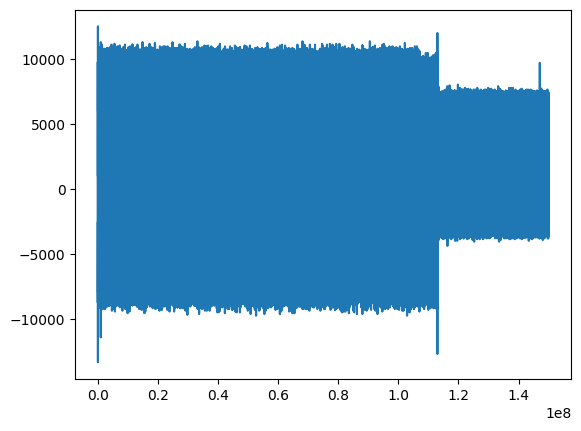

In [7]:
with h5py.File(PATH_TO_DATA) as file_handler:
    plt.plot(file_handler["em_curves"][0,:])
    plt.show()

Zooming a bit, we clearly see the preliminary operations then the first iterations of the loop on the scalar bits.

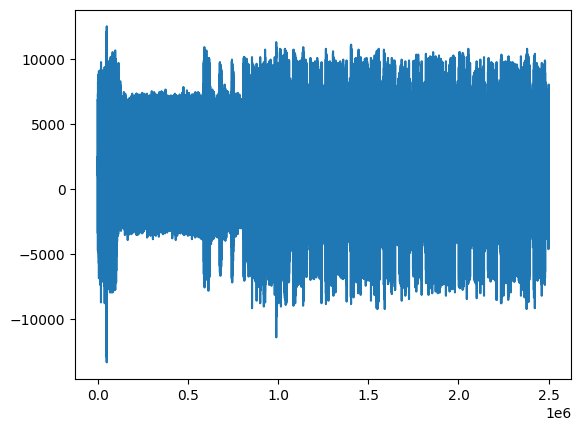

In [9]:
with h5py.File(PATH_TO_DATA) as file_handler:
    plt.plot(file_handler["em_curves"][0,:2_500_000])
    plt.show()

More information on the traces and the attack can be found in the dedicated notebook. The remainder of this document will focus on more details about the setup. The goal is that an interested reader can be sure about what the content of the dataset corresponds to.

## More Details on the Setup

### Bench Description
The bench used for acquisitions is quite classical with details provided as attributes of the dataset.
Here is a simple schematic view.

![Bench overview](img/bench.png)

### Probe Position
As can be seen in the dataset attributes, the FPGA chip has been decapsulated.
To help interested researchers to reproduce/extend the presented work, we provide hereafter a photo of the probe position on the die.

![Probe position](img/probe_position.png)

### Interaction with *IPECC*
An important element also is how the IP has been triggered by the bench.

A small FSM has been programmed over the available driver as a **bare metal** program flashed on an SD card. 

A brief overview of the (very simple) protocol used is presented in the following picture.

![Interaction with target](img/dut_protocol.png)

The trigger output provided by IPECC has been redirected to a GPIO pin and used to launch curve acquisition on the oscilloscope.